In [2]:
# loading libraries for data manipulation
import numpy as np
import pandas as pd

# loading libraries for data visualization
import matplotlib.pyplot as plt
from plotnine import *

# import tensorflow and keras packages
import tensorflow as tf
from tensorflow import keras

import warnings
warnings.filterwarnings('ignore')

We will load the CIFAR-10 dataset that contains small RGB images across 10 classes. 

In [3]:
# Load CIFAR-10 data from keras.datasets
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

num_classes = 10

# Normalize images
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# Convert labels to one-hot if desired
y_train_cat = keras.utils.to_categorical(y_train, num_classes)
y_test_cat  = keras.utils.to_categorical(y_test, num_classes)

print("Train shape:", x_train.shape, "Test shape:", x_test.shape)


Train shape: (50000, 32, 32, 3) Test shape: (10000, 32, 32, 3)


Let's build a baseline CNN to predict the classes. 

In [4]:
# Define architecture
baseline_model = keras.Sequential([
    keras.layers.Conv2D(32,(3,3),padding="same",
                        activation="relu",
                        input_shape=(32,32,3)),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(64,(3,3),padding="same",
                            activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(128,(3,3),padding="same",
                            activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(num_classes,activation="softmax")
])

# Define compilation parameters
baseline_model.compile(loss="categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

# Train model
baseline_model.fit(x_train,y_train_cat,
                           epochs=5,verbose=1,batch_size=64,
                           validation_data=(x_test,y_test_cat))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.4089 - loss: 1.6119 - val_accuracy: 0.5641 - val_loss: 1.2490
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5684 - loss: 1.2103 - val_accuracy: 0.6343 - val_loss: 1.0462
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6328 - loss: 1.0454 - val_accuracy: 0.6613 - val_loss: 0.9549
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.6712 - loss: 0.9344 - val_accuracy: 0.6679 - val_loss: 0.9721
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6988 - loss: 0.8574 - val_accuracy: 0.7011 - val_loss: 0.8611


In [5]:
# look at the model architecture
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,104 (2.58 MB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 450,070 (1.72 MB)

Let's now apply some data augmentation to introdce variations in the images the model sees. We can apply a series of augmentations to the inputs. 

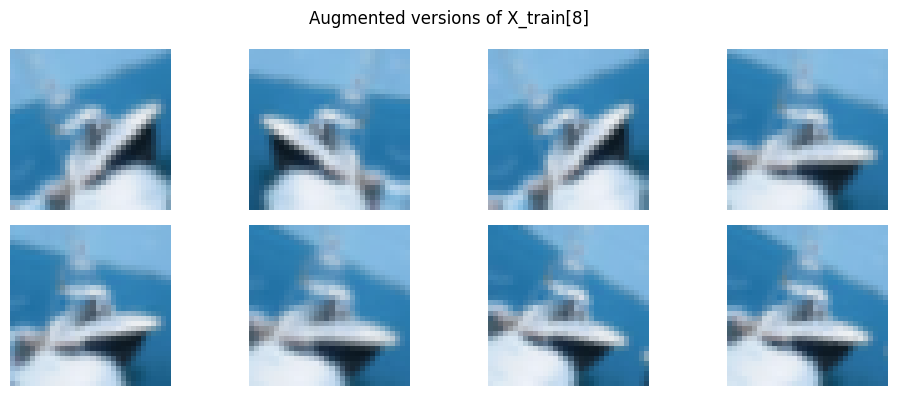

In [6]:
# Create a new layer of data augmentation
data_augmentation = keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(0.1),
        keras.layers.RandomZoom(0.1)
])

# Test augmentation on a single input image
sample_img = tf.expand_dims(x_train[8], 0)

plt.figure(figsize=(10, 4))
for i in range(8):
    aug_img = data_augmentation(sample_img, training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(aug_img[0])
    plt.axis('off')
plt.suptitle("Augmented versions of X_train[8]")
plt.tight_layout()
plt.show()


Let's now create a new CNN with this data augmentation layer built in. 

In [7]:
# Define architecture
augmented_model = keras.Sequential([
    data_augmentation,
    keras.layers.Conv2D(32,(3,3),padding="same",
                        activation="relu",
                        input_shape=(32,32,3)),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(64,(3,3),padding="same",
                            activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(128,(3,3),padding="same",
                            activation="relu"),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(num_classes,activation="softmax")
])

# Define compilation parameters
augmented_model.compile(loss="categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

# Train model
augmented_model.fit(x_train,y_train_cat,
                           epochs=5,verbose=1,batch_size=64,
                           validation_data=(x_test,y_test_cat))

Epoch 1/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.3750 - loss: 1.6998 - val_accuracy: 0.4897 - val_loss: 1.4132
Epoch 2/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.4860 - loss: 1.4235 - val_accuracy: 0.5708 - val_loss: 1.1816
Epoch 3/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5372 - loss: 1.2919 - val_accuracy: 0.5763 - val_loss: 1.2020
Epoch 4/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5709 - loss: 1.2054 - val_accuracy: 0.6232 - val_loss: 1.0720
Epoch 5/5
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5968 - loss: 1.1432 - val_accuracy: 0.6206 - val_loss: 1.0821


In [8]:
# Model summary showcases how the augmentation layer is utilized
augmented_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (1, 32, 32, 3)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (1, 32, 32, 32)        │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (1, 16, 16, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (1, 16, 16, 64)        │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (1, 8, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (1, 8, 8, 128)         │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (1, 4, 4, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (1, 2048)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 64)                │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (1, 64)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 10)                │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,104 (2.58 MB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 450,070 (1.72 MB)

Let's also view the model's performance against examples from the test data. 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


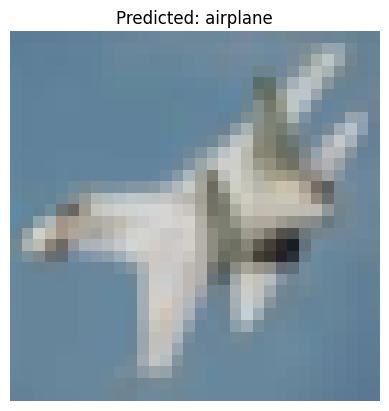

In [11]:
# Classes defined for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer','dog', 'frog', 'horse', 'ship', 'truck']

# Test one image
img = x_test[10]  # Already normalized if you followed previous steps
img_batch = np.expand_dims(img, axis=0)  # Shape: (1, 32, 32, 3)

# Predictions are provided as probabilities per class, we pick the highest one
pred = augmented_model.predict(img_batch)
pred_class = np.argmax(pred)

plt.imshow(img)
plt.title(f"Predicted: {class_names[pred_class]}")
plt.axis('off')
plt.show()

Instead of the sequential way of defining the architecture of a Neural Network, you can also use the functional way. Here, we iteratively add layers and blocks to a variable.

In [12]:
# Define the input layer
inputs = keras.Input(shape=(32, 32, 3))

# Data augmentation (only applied during training)
x = data_augmentation(inputs)

# Conv block 1
x = keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
x = keras.layers.MaxPooling2D((2, 2))(x)

# Conv block 2
x = keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = keras.layers.MaxPooling2D((2, 2))(x)

# Conv block 3
x = keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = keras.layers.MaxPooling2D((2, 2))(x)

# Fully connected
x = keras.layers.Flatten()(x)
x = keras.layers.Dense(64, activation='relu')(x)
outputs = keras.layers.Dense(10, activation='softmax')(x)

# Create the model
model = keras.Model(inputs=inputs, outputs=outputs)

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(
    x_train, y_train_cat,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test_cat)
)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.4104 - loss: 1.6210 - val_accuracy: 0.5238 - val_loss: 1.3028
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5353 - loss: 1.3019 - val_accuracy: 0.5511 - val_loss: 1.2978
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.5876 - loss: 1.1666 - val_accuracy: 0.5825 - val_loss: 1.2252
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6171 - loss: 1.0840 - val_accuracy: 0.6375 - val_loss: 1.0509
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.6427 - loss: 1.0230 - val_accuracy: 0.6592 - val_loss: 0.9800
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6551 - loss: 0.9807 - val_accuracy: 0.6796 - val_loss: 0.9226
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.6700 - loss: 0.9429 - val_accuracy: 0.6804 - val_loss: 0.9177
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.6803 - loss: 0.9128 - val_acc

One advantage of defining the model this way is to allow us to extract layers from the model after training. This can be used to generate feature maps between layers. 

In [13]:
# Create model for intermediate activations
layer_outputs = [layer.output for layer in model.layers if 'conv' in layer.name]
activation_model = keras.models.Model(inputs=model.input, outputs=layer_outputs)

# Get activations by "predicting" for each conv layer
activations = activation_model.predict(img_batch)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


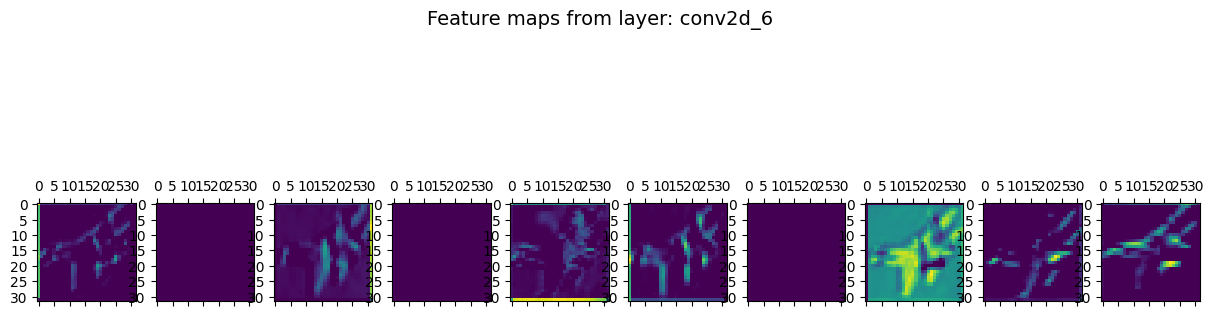

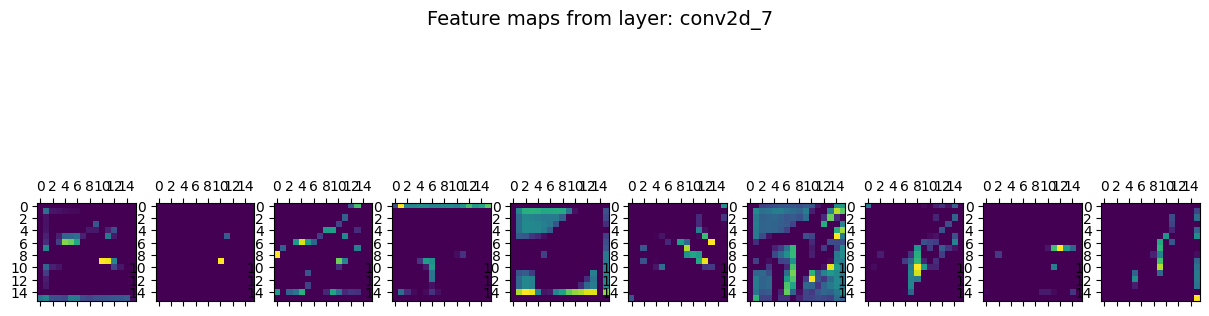

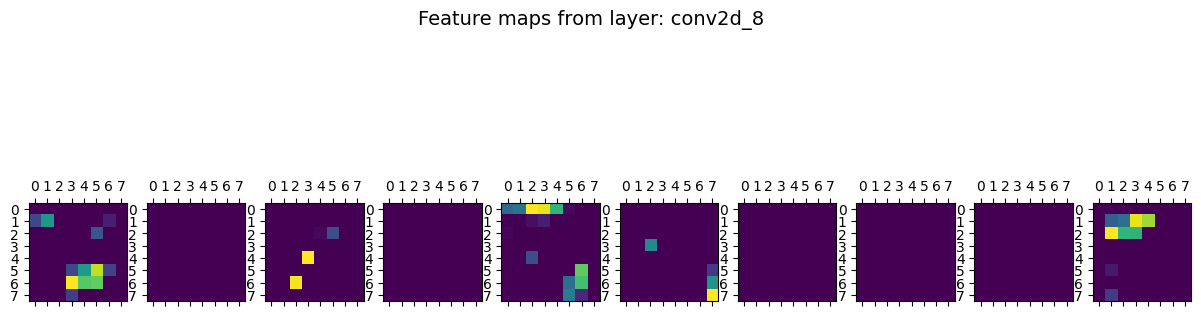

In [14]:
# Display feature maps (the activations produced by convolutional layers)
def plot_feature_maps(activations, layer_names, image_index=0, max_channels=10):
    # Pair each activation tensor with its corresponding layer name
    for layer_name, activation in zip(layer_names, activations):
        num_channels = activation.shape[-1]  # Number of feature maps in this layer
        size = activation.shape[1]           # Height of each feature map

        # Limit the plot to max_channels, even if the layer has more
        display_channels = min(max_channels, num_channels)

        # Create one subplot for each feature map being displayed
        fig, axes = plt.subplots(1, display_channels, figsize=(15, 5))
        fig.suptitle(f'Feature maps from layer: {layer_name}', fontsize=14)

        # Show each selected channel for the chosen image
        for i in range(display_channels):
            ax = axes[i]
            ax.matshow(
                activation[image_index, :, :, i],  # Select image and channel
                cmap='viridis'                     # Color map for activation values
            )
            # ax.axis('off')  # Uncomment to hide the axes and tick marks

        plt.show()  # Display this layer's feature maps


# Collect the names of the model's convolutional layers
layer_names = [layer.name for layer in model.layers if 'conv' in layer.name]

# Plot the feature maps for image, showing up to 10 maps per layer
plot_feature_maps(activations, layer_names)

We can also use this mechanism to generate the gradCAM: a heatmap that indicates which parts of the input "activated" the model most. 

In [15]:
import cv2

# Step 1. make a prediction
preds = model.predict(img_batch)
pred_class = np.argmax(preds[0])
print(f"Predicted class: {pred_class}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Predicted class: 0


In [16]:
# Step 2. compute gradient of the class score with respect to the convolution layers
# Here we will use the last convolution layer
last_conv_layer_name = [layer.name for layer in model.layers if 'conv' in layer.name][-1]
last_conv_layer = model.get_layer(last_conv_layer_name)

# Create a model that outputs the last conv layer and predictions
# The weights of this layer are already fitted - no need to retrain
grad_model = tf.keras.models.Model(
    [model.inputs],
    [last_conv_layer.output, model.output]
)

# This tool tracks all computations needed to feed forward an input through the network
# So we can ask it later to calculate the gradient for us efficiently
with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(img_batch)
    loss = predictions[:, pred_class]

# Calculate gradient
grads = tape.gradient(loss, conv_outputs)

# Apply global average pooling over gradients
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))


In [17]:
# Step 3. multiply each channel in the conv output by its gradient importance
conv_outputs = conv_outputs[0] # 1,h,w,c into h,w,c
heatmap = conv_outputs @ pooled_grads[..., tf.newaxis] # matrix multiplication
heatmap = tf.squeeze(heatmap) # h,w

# Normalize heatmap to [0, 1]
heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
heatmap = heatmap.numpy()

# Resize heatmap to match input image
heatmap_resized = cv2.resize(heatmap, (32, 32))

# Convert to RGB
image_rgb = np.uint8(255 * img)

# Apply colormap
heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(image_rgb, 0.6, heatmap_color, 0.4, 0)


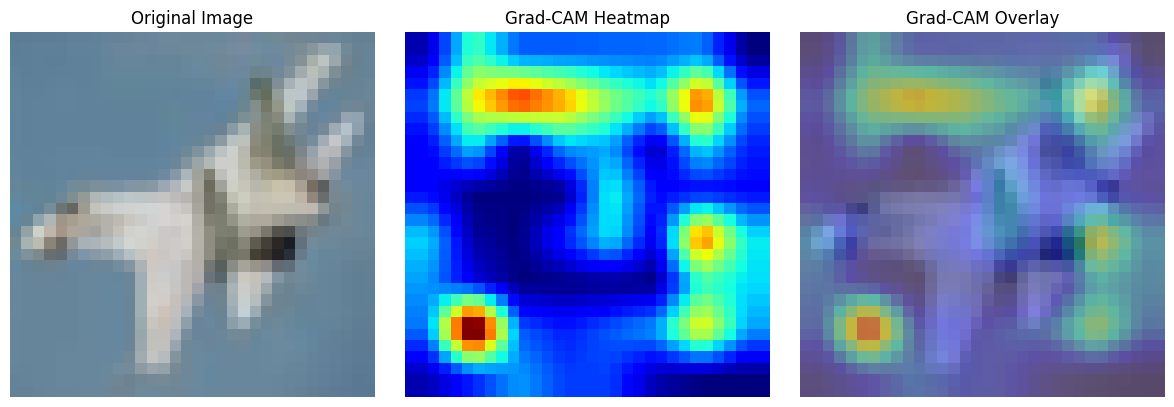

In [18]:
# Step 4. plot heatmap

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Original Image")
plt.imshow(img)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Grad-CAM Heatmap")
plt.imshow(heatmap_resized, cmap='jet')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Grad-CAM Overlay")
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()